# 案例：A2A 智能体封装、发现与 Supervisor 协作

> Last updated: 2026-11-22

## 核心学习目标

本案例以 Chapter-6 已实现的 `HotelAgent` 和任务规划能力为基础，说明如何将本地智能体封装为遵循 A2A 协议、可被第三方长期托管并发现的远程服务；随后将多个 A2A 智能体注册到 LangGraph Supervisor 中完成协作。

## 案例设计

### Part I：发布一个 A2A Agent

- **目的**：将 Chapter-6 的 `HotelAgent` 由本地 LangGraph Agent 封装为通过 HTTP 可发现的 A2A Agent，并理解 Agent Card、Message、Task 状态的含义。
- **适用场景**：业务智能体需要被多个调用方、多台设备或第三方系统复用，且运行边界、模型配置和内部工具不希望暴露给调用方。

### Part II：用 LangGraph Supervisor 组织多个 A2A Agent

- **目的**：将 Planner 和 Hotel 两个 A2A 服务包装为 LangGraph 子图，由 Supervisor 决定先规划还是直接执行。
- **适用场景**：多个远程智能体需要围绕一个用户请求分工协作，但每个智能体仍独立部署、独立维护。

## 学习重点

1. 理解 Chapter-6 的本地 `HotelAgent` 如何被封装为 A2A Agent。
2. 理解 Agent Card JSON 各字段对“服务发现”和“能力声明”的作用。
3. 掌握 `agents.py`、`agent_cards/*.json` 和 `server.py` 三者的职责分工。
4. 掌握 A2A Client 的发现、流式调用和任务终态判断。
5. 理解 A2A 子图与 LangGraph Supervisor handoff 的协作方式。

### 模块与代码对应关系

| 环节 | 学习内容 | 对应实现 |
|------|----------|----------|
| 业务能力 | 酒店推荐与任务规划 | `Chapter-6/domain_agents.py`、`Chapter-6/task_plan.py` |
| 业务 Agent | 发布为 A2A 服务的业务实现 | `A2A/agents.py` |
| 服务声明 | Agent Card JSON | `A2A/agent_cards/*.json` |
| 服务发布 | Executor、HTTP 路由、实现选择 | `A2A/server.py` |
| 服务发现与调用 | Agent Card 发现、Message、Task 终态 | `A2A/a2a_client.py` |
| 多 Agent 协作 | 远程子图与 Supervisor | `A2A/supervisor.py` |
| 模型访问 | 统一模型创建接口 | 仓库根目录 `llm.py` |

## 0. 环境准备

本案例使用仓库根目录的共享 `.venv`，模型和地图凭据统一配置在仓库根目录的 `.env` 中。

```powershell
uv pip install -r Chapter-7/A2A/requirements.txt
```

# Part I：发布一个 A2A Agent

本部分按“为什么需要 A2A → 发布方需要完成什么 → 如何声明并组装服务 → 启动并验证”的顺序展开。

## 1. 为什么发布 A2A 智能体

### 1.1 Chapter-6 已定义的本地 Agent 及其局限

Chapter-6 的 `HotelAgent` 是一个 LangGraph Agent：它有角色定义、System Prompt 和酒店查询工具。使用它的方式是在同一个 Python 进程里直接调用：

```python
# Chapter-6 中，本地调用方式（示意）
agent = get_domain_agent("HotelAgent")
state = await agent.ainvoke(
    {"messages": [("user", "推荐大同古城附近500元以内的酒店")]}
)
```

该方式可以正常运行，但在更复杂的协作场景中存在明显局限：

1. **框架耦合**：调用方必须了解并依赖 LangGraph Agent 的对象结构，才能完成调用；若 Agent 由其他框架实现，则难以直接集成。
2. **部署耦合**：调用方与 Agent 位于同一进程、同一设备，无法跨主机调用，也无法由第三方独立部署和运维。
3. **能力复用受限**：不同团队、不同技术栈的系统若要复用同一 Agent，需要共享代码与运行环境，边界不清晰。

A2A 的目标是解除上述耦合：调用方不再需要依赖 Agent 的具体实现框架或运行位置，只需通过标准协议向其发送任务。
MCP 与 A2A 的差别在于：MCP 暴露的是工具，调用方需自行决定调用哪个函数；A2A 暴露的是完整 Agent，调用方仅提交任务，由 Agent 自行决定使用哪些工具并生成最终结果。

### 1.2 发布 A2A 智能体需要完成的工作

作为发布方，将一个自定义智能体发布为 A2A 服务通常包含以下步骤：

step1. **准备智能体实现**：本案例直接复用 Chapter-6 已实现的 `HotelAgent`，无需重新开发业务能力。
step2. **声明智能体能力**：编写 Agent Card，声明智能体名称、能力与调用地址。
step3. **将智能体接入 A2A 服务**：组装并启动一个遵循 A2A 协议的 HTTP 服务进程，负责读取 Agent Card、注册协议路由、调用业务 Agent，并维护任务状态。
step4. **启动 A2A 服务并公开访问地址**：本机演示使用 `127.0.0.1`，对外发布时替换为可被其他主机访问的 IP 地址或域名。


## 2. 发布 A2A 智能体

step1“准备智能体实现”直接复用 Chapter-6 已实现的 `HotelAgent`。为使该 Agent 能够被远程调用，还需提供 Agent Card 与 HTTP 服务入口：前者用于声明 Agent 的能力与调用地址，后者负责接收请求并转交给业务 Agent。



### 2.1 编写 Agent Card：声明智能体能力

如`agent_cards/hotel_agent.json`，调用方在发送请求前读取该文件，以确认Agent的名称、能力与调用地址：

```json
{
  "name": "HotelAgent",
  "description": "根据城市、位置偏好和每晚预算推荐酒店。",
  "version": "1.0.0",
  "supportedInterfaces": [
    {
      "url": "http://127.0.0.1:9012/",
      "protocolBinding": "JSONRPC",
      "protocolVersion": "1.0"
    }
  ],
  "capabilities": {
    "streaming": true,
    "pushNotifications": false
  },
  "defaultInputModes": ["text", "text/plain"],
  "defaultOutputModes": ["text", "text/plain"],
  "skills": [
    {
      "id": "recommend_hotel",
      "name": "Recommend hotels",
      "description": "根据城市、位置偏好和每晚预算检索酒店候选...",
      "tags": ["hotel", "input:city", "output:hotels"],
      "examples": ["推荐一家大同古城附近的酒店。"]
    }
  ]
}
```

各字段含义如下：

- `name`：Agent 名称，此处为 `HotelAgent`。
- `description`：Agent 的功能说明，即酒店推荐。
- `supportedInterfaces`：智能体暴露的协议接口；其中 `url` 为调用入口，当前使用 `http://127.0.0.1:9012/`，`protocolBinding` 表明采用 JSONRPC 协议。
- `capabilities`：智能体的能力声明，`streaming` 表示支持流式输出，`pushNotifications` 表示是否支持服务端主动推送。
- `defaultInputModes` / `defaultOutputModes`：智能体默认支持的输入与输出内容类型。
- `skills`：Agent 可执行的技能列表；`input:*`、`output:*` 标签用于 Planner 判断任务间的输入输出依赖，为本教程的教学约定。

需要说明的是，本教程在本机演示 Agent 发布，因此 `url` 使用 `127.0.0.1`。若需向其他主机开放服务，应将该地址替换为服务器的 IP 地址或域名，并确保对应端口可被外部访问。



### 2.2 server.py：组装并启动服务

`server.py` 负责读取 Agent Card，根据 `name` 字段选择对应的业务 Agent，并启动 HTTP 服务。

```python
# server.py
def get_agent(agent_name):
    return {
        "HotelAgent": HotelRecommendationAgent,
    }[agent_name]()
```

In [6]:
# 准备运行环境：配置跨章节导入路径。
from pathlib import Path
import sys
print("Python:", sys.executable)

candidates = (
    Path.cwd(),
    Path.cwd() / "Chapter-7",
    Path.cwd().parent,
)
CHAPTER7_DIR = next(
    (
        candidate.resolve()
        for candidate in candidates
        if candidate.name == "Chapter-7"
        and (candidate / "README.md").is_file()
    ),
    None,
)
if CHAPTER7_DIR is None:
    raise RuntimeError("请从仓库根目录或 Chapter-7 启动 Notebook")

A2A_DIR = CHAPTER7_DIR / "A2A"
if str(A2A_DIR) not in sys.path:
    sys.path.insert(0, str(A2A_DIR))

from a2a_client import A2AClient, discover_agent_card
from a2a.types import TaskState
from process_manager import AgentProcessManager
import settings

print("A2A runtime loaded:", A2A_DIR)

Python: e:\Book\agent-systems-book\.venv\Scripts\python.exe
A2A runtime loaded: E:\Book\agent-systems-book\Chapter-7\A2A


In [7]:
# 查看 server.py 中根据 Agent Card 选择业务实现的关键逻辑。
import inspect

from server import get_agent

# get_agent：根据 Agent Card 中的 name 字段，返回对应的业务 Agent 实现。
print(inspect.getsource(get_agent))

def get_agent(agent_name: str) -> Any:
    """Map a public Agent Card name to its business implementation."""
    agents: dict[str, Any] = {
        "TravelPlannerAgent": TravelPlannerAgent,
        "HotelAgent": HotelRecommendationAgent,
    }
    try:
        return agents[agent_name]()
    except KeyError as exc:
        raise ValueError(
            f"No implementation registered for Agent Card: {agent_name}"
        ) from exc



### 2.3 启动 A2A 服务

在本 Notebook 中，`AgentProcessManager` 在后台启动 Planner 和 Hotel 两个 A2A 服务进程，并负责等待其就绪及最终关闭。这仅是教学演示使用的便利工具，不属于 A2A 协议本身的内容。

In [8]:
# 启动 Planner 与 Hotel 两个 A2A 服务，并等待其 Agent Card 就绪。
manager = AgentProcessManager()
await manager.start()

print("已启动以下 A2A 服务：")
for service in settings.SERVICE_NAMES:
    print(f"  {service:8s} {settings.service_base_url(service)}")

已启动以下 A2A 服务：
  planner  http://127.0.0.1:64608/
  hotel    http://127.0.0.1:64609/


## 3. 验证发布结果

### 3.1 通过 URL 发现 Agent Card

调用方需要先获得服务的基础 URL（由发布方通过服务目录、接口文档或调用方配置提供），
再访问该 URL 下的 `/.well-known/agent-card.json` 获取 Agent Card。
Agent Card 的 `supportedInterfaces` 中声明了实际的消息调用地址。A2A 只约定发现路径，不会自动发现服务。


本案例中，`server.py` 通过 `create_agent_card_routes` 自动注册上述发现端点。本机演示的基础地址为 `http://127.0.0.1:9012/`，完整发现地址为 `http://127.0.0.1:9012/.well-known/agent-card.json`；对外发布时，将基础地址替换为服务域名或公网 IP 地址即可。

In [9]:
cards = {}
print("agent_cards/hotel_agent.json:")
print(
    (A2A_DIR / "agent_cards" / "hotel_agent.json").read_text(
        encoding="utf-8"
    )
)
for service in settings.SERVICE_NAMES:
    cards[service] = await discover_agent_card(
        settings.service_base_url(service)
    )
    skill_ids = [
        skill["id"]
        for skill in cards[service].get("skills", [])
    ]
    print(
        cards[service]["name"],
        "→",
        skill_ids,
    )

agent_cards/hotel_agent.json:
{
  "name": "HotelAgent",
  "description": "根据城市、位置偏好和每晚预算推荐酒店。",
  "version": "1.0.0",
  "supportedInterfaces": [
    {
      "url": "http://127.0.0.1:9012/",
      "protocolBinding": "JSONRPC",
      "protocolVersion": "1.0"
    }
  ],
  "capabilities": {
    "streaming": true,
    "pushNotifications": false
  },
  "defaultInputModes": [
    "text",
    "text/plain"
  ],
  "defaultOutputModes": [
    "text",
    "text/plain"
  ],
  "skills": [
    {
      "id": "recommend_hotel",
      "name": "Recommend hotels",
      "description": "根据城市、位置偏好和每晚预算检索酒店候选，并给出有字段依据的住宿推荐。",
      "tags": [
        "hotel",
        "recommendation",
        "travel",
        "parallel-safe:false",
        "input:city",
        "input:preferences",
        "input:budget_cny_per_night_max",
        "output:city",
        "output:hotels",
        "output:count",
        "output:data_source"
      ],
      "examples": [
        "推荐一家大同古城附近、预算不超过500元的酒店。"
      ]
    }
  ]
}

Tr

### 3.2 直接调用已发布的 A2A Agent

模拟调用方通过 URL 发送任务，以验证服务能够独立完成并返回结果。

In [10]:
hotel_client = A2AClient(settings.service_base_url("hotel"))
try:
    result = await hotel_client.call(
        "推荐一家大同古城附近、预算不超过500元的酒店。"
    )
finally:
    await hotel_client.close()

print("Task state:", TaskState.Name(result.state))
print(result.text)

Task state: TASK_STATE_COMPLETED
根据您的需求，为您推荐以下3家位于大同古城附近、评分较高的酒店/民宿：

1. **钰雅轩民宿·中式合院别墅(大同古城代王府店)**
   - **地址/位置**：平城区武定街铂蓝五龙巷27院2号
   - **参考价格**：预算范围内（具体价格需实时查询）
   - **评分**：5.0
   - **推荐理由**：位于古城核心区域代王府附近，中式合院别墅风格独特，评分满分，适合体验传统建筑氛围。

2. **云树酒店(大同古城华严寺店)**
   - **地址/位置**：平城区武定北路26号院内共创空间
   - **参考价格**：预算范围内（具体价格需实时查询）
   - **评分**：5.0
   - **推荐理由**：紧邻著名景点华严寺，地理位置便利，评分满分，适合希望近距离游览古迹的游客。

3. **鼓楼客栈(大同鼓楼华严寺店)**
   - **地址/位置**：平城区鼓楼东街39号院
   - **参考价格**：预算范围内（具体价格需实时查询）
   - **评分**：4.9
   - **推荐理由**：坐落于鼓楼东街，靠近鼓楼和华严寺，交通便利且周边生活设施完善，评分高达4.9分。

注：以上酒店均位于大同古城区域内或边缘，符合您的地理位置要求。由于工具未返回具体均价，建议预订前确认实际价格是否在500元预算内。


# Part II：用 LangGraph Supervisor 组织多个 A2A Agent

假设已有其他开发者发布了两个遵循 A2A 协议的智能体：
- `TravelPlannerAgent` 负责任务拆解与依赖分析，
- `HotelAgent` 负责酒店推荐，
且二者均已公开 Agent Card 与服务 URL。
本部分演示如何将这两个远程 A2A Agent 注册给中心调度智能体，并使用 LangGraph 从零构建 Supervisor 完成任务交接。

## 1. 注册远程 A2A Agent 并定义 handoff

注册过程分为三步：为每个远程 A2A Agent 定义 handoff 工具，创建 Supervisor Agent，再将 Supervisor 与两个远程 Agent 组合为一个图。

```python
# supervisor.py（示意）
transfer_to_planner = create_handoff_tool(agent_name="planner_agent")
transfer_to_hotel = create_handoff_tool(agent_name="hotel_agent")

supervisor_agent = create_react_agent(
    model=create_llm(),
    tools=[transfer_to_planner, transfer_to_hotel],
    prompt=SUPERVISOR_PROMPT,
    name="travel_supervisor",
)

graph = StateGraph(MessagesState)
graph.add_node(supervisor_agent)
graph.add_node("planner_agent", planner_node)
graph.add_node("hotel_agent", hotel_node)
graph.add_edge(START, "travel_supervisor")
graph.add_edge("planner_agent", "travel_supervisor")
graph.add_edge("hotel_agent", "travel_supervisor")
```

`create_handoff_tool` 返回一个交接工具：它使用 `Send(agent_name, agent_input)` 将当前子任务的 `task_description` 单独发送给目标 Agent，并通过 `graph=Command.PARENT` 将控制权交回父图。两个工具的描述分别写清 `planner_agent` 会返回按依赖关系重排的执行顺序，以及 `hotel_agent` 只处理单个城市的酒店推荐。`planner_node` 在调用远程服务后，会把 Planner 返回的完整 JSON 过滤为按执行顺序排列的子任务清单，再交给 Supervisor，避免长 JSON 让 Supervisor 反复重新规划。`hotel_node` 同样由 `create_remote_agent_node` 创建，内部通过 A2A Client 调用远程服务。

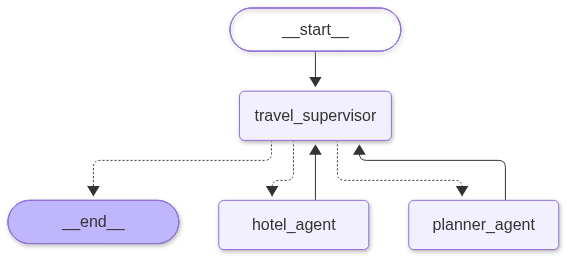

In [11]:
# 绘制 Supervisor 交互图。
from IPython.display import Image, display

from supervisor import build_supervisor

supervisor_graph = build_supervisor()
display(Image(supervisor_graph.get_graph().draw_mermaid_png()))

In [12]:
from langchain_core.messages import convert_to_messages

def pretty_print_message(message, indent=False):
    pretty_message = message.pretty_repr(html=True)
    if not indent:
        print(pretty_message)
        return

    indented = "\n".join(
        "\t" + line for line in pretty_message.split("\n")
    )
    print(indented)

def pretty_print_messages(update, last_message=False):
    is_subgraph = False
    if isinstance(update, tuple):
        ns, update = update
        if len(ns) == 0:
            return

        graph_id = ns[-1].split(":")[0]
        print(f"Update from subgraph {graph_id}:")
        print("\n")
        is_subgraph = True

    for node_name, node_update in update.items():
        update_label = f"Update from node {node_name}:"
        if is_subgraph:
            update_label = "\t" + update_label

        print(update_label)
        print("\n")

        messages = convert_to_messages(
            node_update.get("messages", [])
        )
        if last_message:
            messages = messages[-1:]

        for message in messages:
            pretty_print_message(message, indent=is_subgraph)
        print("\n")

query_text = (
    "我想要先去江苏南京再去苏州，给我推荐酒店，预算不超过1000元/晚"
)
config = {
    "configurable": {"thread_id": "chapter7-a2a-supervisor"}
}

async for chunk in supervisor_graph.astream(
    {"messages": [{"role": "user", "content": query_text}]},
    config=config,
    subgraphs=True,
):
    pretty_print_messages(chunk, last_message=True)

state = await supervisor_graph.aget_state(config)
messages = state.values["messages"]
planner_calls = sum(
    getattr(message, "name", None) == "planner_agent"
    for message in messages
)
route = [
    message.name
    for message in messages
    if getattr(message, "name", None)
    in {"planner_agent", "hotel_agent"}
]

print(f"planner_agent total: {planner_calls}")
print("Route:", " → ".join(route))
print("\n" + str(messages[-1].content))

Update from subgraph travel_supervisor:


	Update from node agent:


	================================== Ai Message ==================================
	Name: travel_supervisor
	
	我需要先让 planner_agent 来规划这个旅行任务，确定执行顺序和子任务列表。
	Tool Calls:
	  transfer_to_planner_agent (call_4e38eb4e0ff44058bf8dfbd7)
	 Call ID: call_4e38eb4e0ff44058bf8dfbd7
	  Args:
	    task_description: 用户想要先去江苏南京再去苏州，预算不超过1000元/晚，需要推荐酒店。请按照依赖关系重排并给出执行顺序的酒店推荐子任务列表。


Update from subgraph travel_supervisor:


	Update from node agent:


	================================== Ai Message ==================================
	Name: travel_supervisor
	
	我将按照执行顺序，先处理南京的酒店推荐任务。
	Tool Calls:
	  transfer_to_hotel_agent (call_a408c2f553bc4799b18f52e5)
	 Call ID: call_a408c2f553bc4799b18f52e5
	  Args:
	    task_description: 根据城市南京、位置偏好市中心或主要旅游景点附近、每晚预算不超过1000元推荐酒店


Update from subgraph travel_supervisor:


	Update from node agent:


	================================== Ai Message ==================================
	Name: travel_supervisor

## 3. 小结

- 发布：通过 Agent Card 声明能力，由 `server.py` 启动遵循 A2A 协议的 HTTP 服务。
- 调用：调用方凭服务 URL 获取 Agent Card，并通过 Message、Artifact 与 Task 状态完成交互。
- 协作：将远程 A2A Agent 注册给 LangGraph Supervisor，通过 handoff 工具安排 Planner 与 Hotel 的任务交接。

In [13]:
manager.stop()
print("Local teaching services stopped.")

Local teaching services stopped.


## 4. 扩展练习：为 Supervisor 注册更多 A2A 智能体

本案例的 Supervisor 目前只协调 `planner_agent` 与 `hotel_agent`。请参照 Part II 的步骤，把更多遵循 A2A 协议的智能体接入同一个 Supervisor，完成更复杂的旅行任务。

**扩展方向**

- 新增 `FlightAgent`、`WeatherAgent` 等业务智能体，并为每个智能体准备对应的 Agent Card。
- 扩展 `_prepare_planner_query`，让 Planner 能发现新智能体的能力。
- 在 `build_supervisor` 中为每个新智能体创建 handoff 工具和远程节点，并更新 Supervisor 提示词。
- 设计一个更复杂的用户请求，例如“先查天气和机票，再安排景点与酒店”，观察 Supervisor 如何按 Planner 给出的执行顺序在多个智能体之间切换。

**发布并共享你的智能体**

- 将 `server.py` 的监听地址设为 `0.0.0.0`，以便接受外部连接；Agent Card 中对外暴露的 URL 应使用运行主机的本机 IP（局域网 IP）或公网 IP。
- 把公开的 Agent Card URL 发给一起学习的同学，对方在 `settings.A2A_*_URL` 或自己的 Supervisor 配置中填入该地址，即可像调用本地服务一样调用你的智能体。
- 部署到可公开访问的设备时，请同时考虑鉴权、HTTPS 等访问控制，避免暴露未受保护的服务与密钥。